# Model evaluation
Held-out performance, threshold trade-offs and a comparison with a rules checklist. Automated gates for the same numbers live in `3_Model/evaluation` (`run_tests.py --suite model`).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "3_Model").exists():
    ROOT = ROOT.parent
for p in ("3_Model", "3_Model/training", "4_Backend/utils"):
    sys.path.insert(0, str(ROOT / p))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


In [2]:
import json
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix
from risk_scoring import RiskScorer
scorer = RiskScorer()
test = pd.read_csv(ROOT / '3_Model/saved_models/test_set.csv')
scores = scorer._scores(test)
y = test.is_fraud.values
json.dumps({k: scorer.metrics[k] for k in ('roc_auc', 'pr_auc')})

'{"roc_auc": 0.9975, "pr_auc": 0.98}'

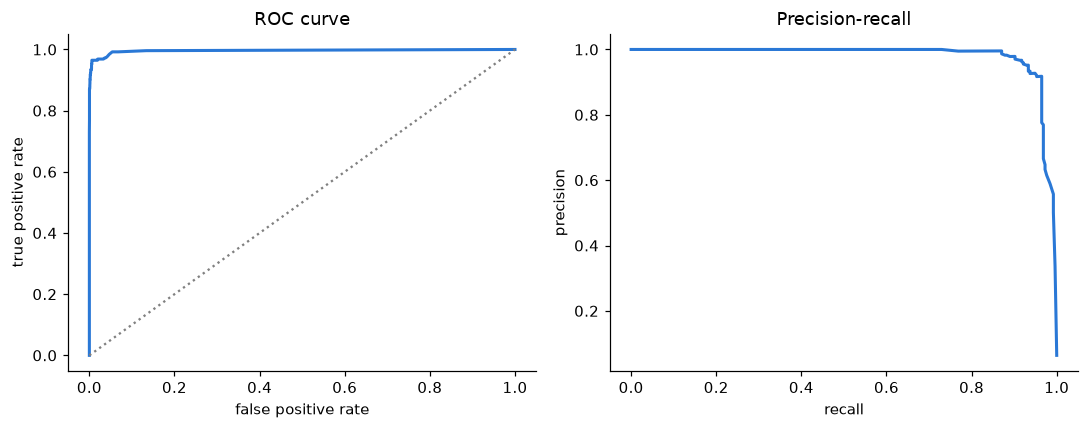

In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y, scores)
a.plot(fpr, tpr, color=BLUE, lw=2); a.plot([0, 1], [0, 1], ls=':', c='gray')
a.set(title='ROC curve', xlabel='false positive rate', ylabel='true positive rate')
p, r, _ = precision_recall_curve(y, scores)
b.plot(r, p, color=BLUE, lw=2); b.set(title='Precision-recall', xlabel='recall', ylabel='precision')
plt.tight_layout()

## Threshold trade-off
What each review threshold means for a small shop: how many orders to check, how much fraud is caught.

In [4]:
rows = []
for t in (10, 20, 30, 40, 50, 60, 70, 80, 90):
    f = scores >= t
    rows.append({'threshold': t, 'orders_flagged': int(f.sum()), 'flag_rate': f.mean(), 'precision': (y[f] == 1).mean() if f.any() else np.nan,
                 'recall': f[y == 1].mean(), 'fraud_$_caught': test.amount[f & (y == 1)].sum()})
pd.DataFrame(rows).round(3)

,threshold,orders_flagged,flag_rate,precision,recall,fraud_$_caught
0,10,355,0.089,0.696,0.969,56843.05
1,20,307,0.077,0.801,0.965,56787.57
2,30,276,0.069,0.891,0.965,56787.57
3,40,273,0.068,0.901,0.965,56787.57
4,50,269,0.067,0.914,0.965,56787.57
5,60,264,0.066,0.920,0.953,56255.81
6,70,255,0.064,0.933,0.933,54848.45
7,80,241,0.060,0.967,0.914,52507.16
8,90,225,0.056,0.987,0.871,51469.71


In [5]:
tn, fp, fn, tp = confusion_matrix(y, scores >= 30).ravel()
pd.DataFrame([[tn, fp], [fn, tp]], index=['actual legit', 'actual fraud'], columns=['approved', 'flagged'])

,approved,flagged
actual legit,3705,30
actual fraud,9,246


## Versus a hand-written rules checklist

In [6]:
sys.path.insert(0, str(ROOT / '3_Model'))
from evaluation.model_checks import rules_score
from sklearn.metrics import average_precision_score
{'model PR-AUC': round(average_precision_score(y, scores), 3), 'rules PR-AUC': round(average_precision_score(y, rules_score(test)), 3)}

{'model PR-AUC': 0.978, 'rules PR-AUC': 0.845}